# Directional Implicit Optimizer Experiment

This notebook runs an experiment using the new `DirectionalImplicitMultipleSystemOptimizer`, which applies implicit gradient reasoning along the steepest-force direction.

In [23]:
import sys
import os
sys.path.append('..')

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import DirectionalImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_systems, _random_spring_ff_param

In [24]:
# Experiment configuration
systemN = 40
N = 20
N_pairs = 50
max_Za = 5
fixed_atom_indices = [0, 1, 2]

# Generate random spring systems and target parameters
Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
k, r0 = _random_spring_ff_param(max_Za, r0_max=10, k_max=10)

ff = SpringFF(max_Za)
ff.reset_parameters(k, r0)
params_star = copy.deepcopy(ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

# Create the directional implicit optimizer
optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)

In [25]:
# Perturb parameters and run optimization
ff.reset_parameters(torch.abs(k.clone() + 3 * torch.randn_like(k)), torch.abs(r0.clone() + 3 * torch.randn_like(r0)))
params_0 = copy.deepcopy(ff.state_dict())

print('start params k mean', params_0['k'].mean().item(), 'r0 mean', params_0['r0'].mean().item())
print('target params k mean', params_star['k'].mean().item(), 'r0 mean', params_star['r0'].mean().item())

new_params = optimizer.optimize(params_0, epoch=60001, print_period=10000, e_size=0.5, eN=11, sg=2)

print('done')

start params k mean 5.299025572095491 r0 mean 4.724264233756344
target params k mean 4.588329812719059 r0 mean 4.669826487385689


  0%|          | 50/60001 [00:00<02:00, 498.50it/s]

Iteration 0, directional implicit loss: 1.033762e+16, valid_count: 3


 17%|█▋        | 10104/60001 [00:16<01:19, 629.16it/s]

Iteration 10000, directional implicit loss: 1.562740e+12, valid_count: 3


...

Iteration 40000, directional implicit loss: 2.422640e+10, valid_count: 3


 83%|████████▎ | 50082/60001 [01:21<00:16, 616.78it/s]

Iteration 50000, directional implicit loss: 5.063683e+07, valid_count: 3


100%|██████████| 60001/60001 [01:38<00:00, 607.94it/s]

Iteration 60000, directional implicit loss: 9.271001e+07, valid_count: 3
done


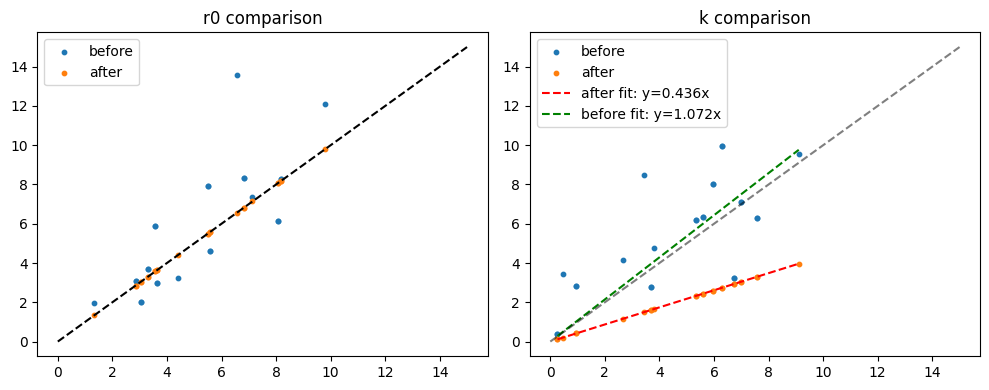

Slope before: 1.0724, slope after: 0.4355


In [27]:
import numpy as np
# Compare the learned parameters before and after optimization
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(params_star['r0'][1:, 1:].detach().reshape(-1).cpu().numpy(), params_0['r0'][1:, 1:].detach().reshape(-1).cpu().numpy(), label='before', s=10)
plt.scatter(params_star['r0'][1:, 1:].detach().reshape(-1).cpu().numpy(), new_params['r0'][1:, 1:].detach().reshape(-1).cpu().numpy(), label='after', s=10)
plt.plot([0, 15], [0, 15], 'k--')
plt.title('r0 comparison')
plt.legend()

plt.subplot(1, 2, 2)
star_k = params_star['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_k = params_0['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_k = new_params['k'][1:, 1:].detach().reshape(-1).cpu().numpy()

plt.scatter(star_k, before_k, label='before', s=10)
plt.scatter(star_k, after_k, label='after', s=10)

# Fit proportional relation k_result = a * k_target
slope_before = (star_k * before_k).sum() / (star_k * star_k).sum()
slope_after = (star_k * after_k).sum() / (star_k * star_k).sum()
line_x = np.array([star_k.min(), star_k.max()])
plt.plot(line_x, slope_after * line_x, 'r--', label=f'after fit: y={slope_after:.3f}x')
plt.plot(line_x, slope_before * line_x, 'g--', label=f'before fit: y={slope_before:.3f}x')

plt.plot([0, 15], [0, 15], 'k--', alpha=0.5)
plt.title('k comparison')
plt.legend()
plt.tight_layout()
plt.show()
print(f'Slope before: {slope_before:.4f}, slope after: {slope_after:.4f}')